# 01 — Exploration et contrôle des données
Source : `results/data_checks.json` (`python -m birdshift.cli.prepare_data`), `data/raw/cache/index.parquet`. Détails : `docs/01_data.md`.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
R, F = ROOT / "results", ROOT / "figures"
pd.set_option("display.precision", 3); pd.set_option("display.width", 200)
def fig(name):
    p = F / f"{name}.png"
    display(Image(str(p))) if p.exists() else print("missing figure:", p.name)
def csv(name):
    p = R / name
    return pd.read_csv(p) if p.exists() else print("missing table:", p.name)

In [2]:
checks = json.load(open(R / 'data_checks.json'))
pd.DataFrame({k: v for k, v in checks.items() if k != 'global'}).T[['n','n_classes','per_class_min','per_class_max','labels_match_parquet_order','domain','months','missing_gps']]

,n,n_classes,per_class_min,per_class_max,labels_match_parquet_order,domain,months,missing_gps
S_train,6595,100,50,102,True,[S],"[5, 6, 7]",0
S_val,500,100,5,5,True,[S],"[5, 6, 7]",0
S_hold,500,100,5,5,True,[S],"[5, 6, 7]",0
S_test,1000,100,10,10,True,[S],"[5, 6, 7]",0
A_hold,500,100,5,5,True,[A],"[8, 9, 10]",0
A_test,1000,100,10,10,True,[A],"[8, 9, 10]",0
W_hold,500,100,5,5,True,[W],"[1, 2, 11, 12]",0
W_test,1000,100,10,10,True,[W],"[1, 2, 11, 12]",0
P_hold,500,100,5,5,True,[P],"[3, 4]",0
P_test,1000,100,10,10,True,[P],"[3, 4]",0


In [3]:
checks['global']

{'n_rows': 29950,
 'n_pool': 16855,
 'files_unique': True,
 'no_file_shared_between_splits': True,
 'y_to_name_matches_classes_json': True}

In [4]:
sys.path.insert(0, str(ROOT / 'src'))
from birdshift import data
idx = data.index()
pd.crosstab(idx['dom'], idx['m'])

m,1,2,3,4,5,6,7,8,9,10,11,12
dom,,,,,,,,,,,,
A,0,0,0,0,0,0,0,1987,1908,1451,0,0
P,0,0,2853,4164,0,0,0,0,0,0,0,0
S,0,0,0,0,3553,2605,2437,0,0,0,0,0
W,2414,2357,0,0,0,0,0,0,0,0,1710,1967
X,50,35,65,49,41,52,62,47,48,33,27,35


Les domaines sont définis par le mois ; `X` = hors Amérique du Nord (jamais utilisé). Le pool (`split` vide) n'a pas d'image mais garde GPS + date : il sert au prior géo-temporel.

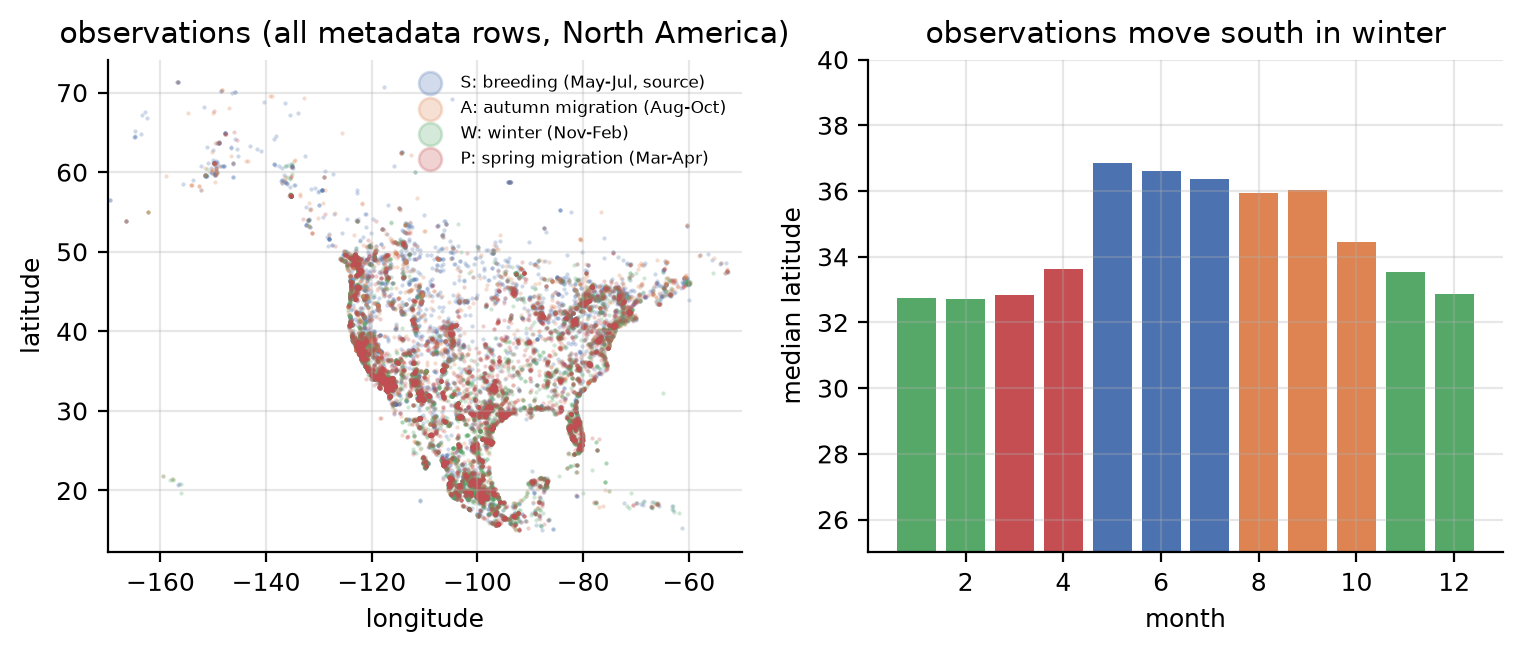

In [5]:
fig('01_data_map_latitude')

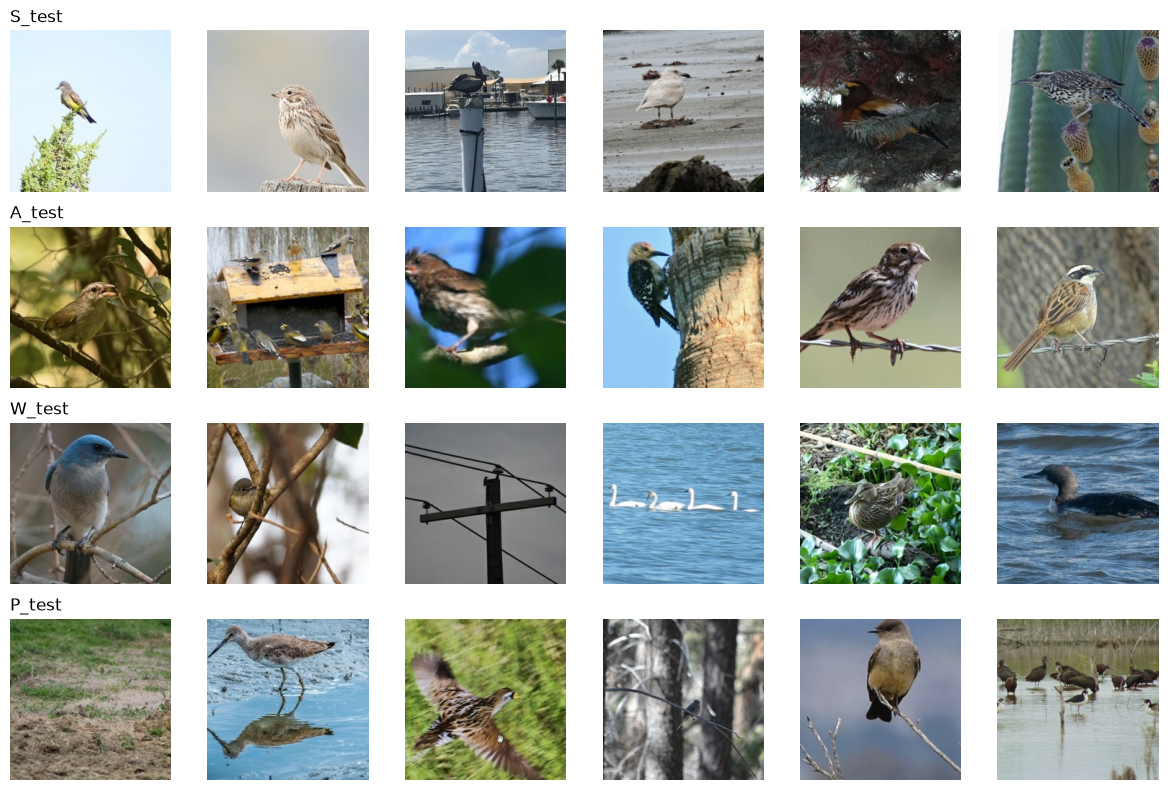

In [6]:
import matplotlib.pyplot as plt
fig_, ax = plt.subplots(4, 6, figsize=(12, 8))
for r, s in enumerate(['S_test','A_test','W_test','P_test']):
    imgs = data.images(s)
    for c in range(6):
        ax[r, c].imshow(imgs[c * 37]); ax[r, c].axis('off')
    ax[r, 0].set_title(s, loc='left')
plt.tight_layout()

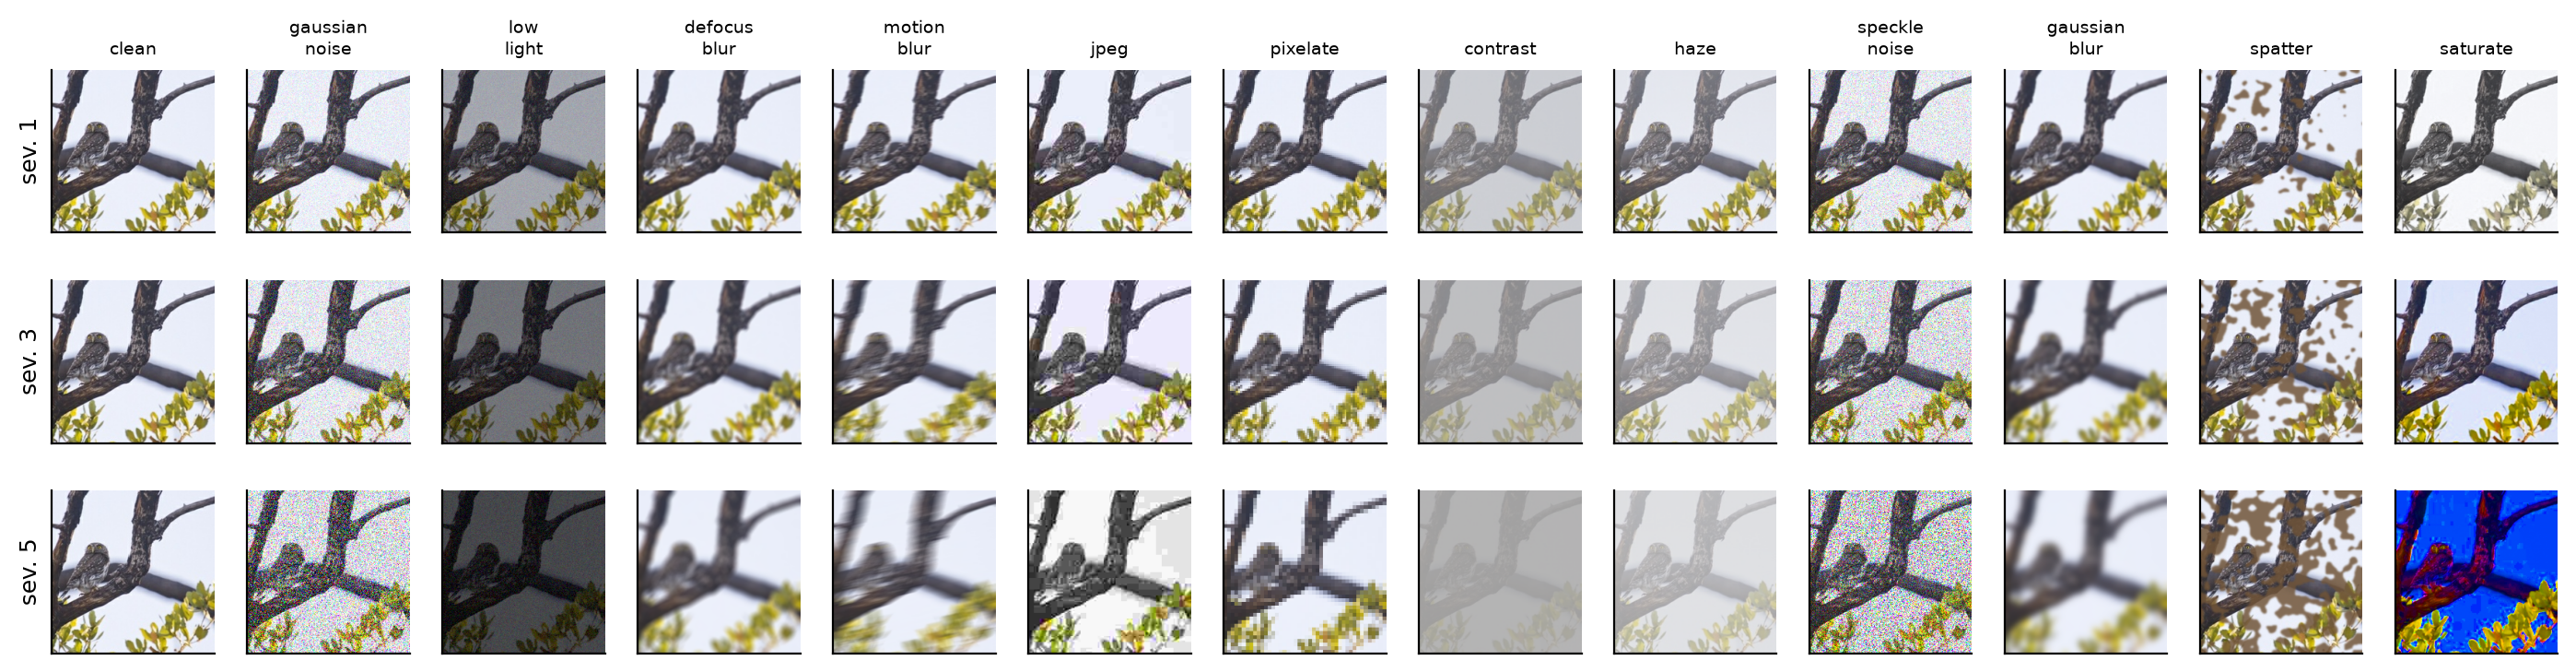

In [7]:
fig('03_corruption_examples')